# 05 · Initial Evaluation and Model Selection

**Round 1 walkthrough:** compare measured metrics, select the provisional model based on the training-trip holdout, and show the first HMM/Viterbi tradeoff. Student-test results are development metrics only, not evaluator results.

In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd()
if not (ROOT/"src").exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/"src"))
DATA=ROOT/"data"/"Student folder"
print("Project:",ROOT,"| data folder available:",DATA.exists())

Project: /Users/yashas/Documents/Codex/2026-11-18/referenced-chatgpt-conversation-this-is-an-2/ML_hackathon | data folder available: True


In [2]:
import pandas as pd, json
from IPython.display import IFrame,display
comparison=pd.read_csv(ROOT/"outputs"/"model_comparison.csv")
route_summary=json.loads((ROOT/"outputs"/"route_decoder_comparison.summary.json").read_text())
display(comparison)
print("Route decoder summary:",route_summary)

,model,validation_top1_accuracy,validation_candidate_miss_rate,validation_observations,student_test_top1_accuracy,student_test_candidate_miss_rate,student_test_observations,training_seconds,validation_candidate_macro_f1,validation_candidate_log_loss,validation_inference_seconds,student_test_candidate_macro_f1,student_test_candidate_log_loss,student_test_inference_seconds
0,Nearest road segment,0.553675,0.075697,39460,0.534760,0.063518,19160,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Logistic Regression,0.552230,0.075697,39460,0.565031,0.063518,19160,0.047696,0.630141,0.417850,0.009601,0.602161,0.472215,0.004669
2,KNN,0.607932,0.075697,39460,0.656942,0.063518,19160,0.001354,0.696515,0.569430,1.012468,0.725147,0.541349,0.470851
3,Decision Tree,0.688672,0.075697,39460,0.729384,0.063518,19160,0.582228,0.798948,0.239767,0.014440,0.802399,0.222999,0.007561
4,Random Forest,0.710872,0.075697,39460,0.751409,0.063518,19160,2.374941,0.832297,0.145083,0.374653,0.841437,0.138511,0.183361
5,Hist Gradient Boosting,0.714496,0.075697,39460,0.754489,0.063518,19160,0.514599,0.847828,0.113410,0.219641,0.860882,0.106523,0.114606


Route decoder summary: {'candidate_miss_rate': 0.063517745302714, 'classifier_top1_accuracy': 0.7545407098121085, 'viterbi_top1_accuracy': 0.5763569937369519, 'student_test_trips': 10, 'observations': 19160, 'classifier_direct_arc_continuity_trip_mean': 0.2540884923418488, 'viterbi_direct_arc_continuity_trip_mean': 0.7385736678787568}


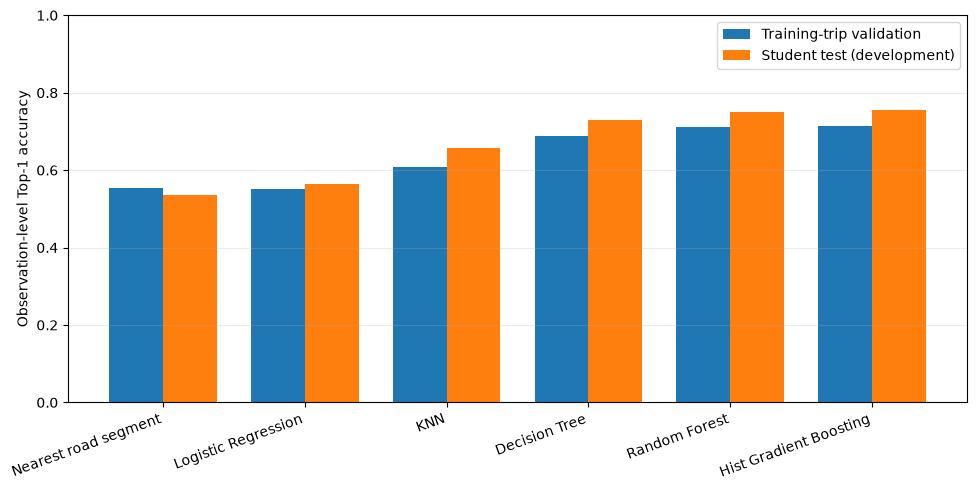

In [3]:
import matplotlib.pyplot as plt
names=comparison["model"].tolist();x=range(len(names));w=.38
fig,ax=plt.subplots(figsize=(10,5))
ax.bar([i-w/2 for i in x],comparison["validation_top1_accuracy"],width=w,label="Training-trip validation")
ax.bar([i+w/2 for i in x],comparison["student_test_top1_accuracy"],width=w,label="Student test (development)")
ax.set_xticks(list(x),names,rotation=20,ha="right");ax.set_ylabel("Observation-level Top-1 accuracy");ax.set_ylim(0,1);ax.legend();ax.grid(axis="y",alpha=.25);fig.tight_layout()

## Why the initial model is Hist Gradient Boosting

It leads the held-out training trips at **71.45% Top-1**, narrowly above Random Forest at **71.09%**. Student-test Top-1 is **75.45%** versus **75.14%** for Random Forest, with a measured inference time of **0.108 s** versus **0.192 s**. The small validation margin means this is provisional; group-aware cross-validation and hyperparameter tuning are still required.

## HMM/Viterbi tradeoff

Across 10 student-test trips, classifier Top-1 is **75.45%**; the initial HMM/Viterbi decoder is **57.64%**. Strict direct-arc continuity rises from **25.41%** to **73.86%**. It makes the route more locally connected but overrules too many correct pointwise predictions. A better transition model should allow plausible multi-arc paths, incorporate travel time and distance, and be tuned only on allowed development data.

In [4]:
route_rows=pd.read_csv(ROOT/"outputs"/"route_decoder_comparison.csv")
display(route_rows)
print("Working Folium demo:",ROOT/"maps"/"phase1_demo.html")
display(IFrame(src=str(ROOT/"maps"/"phase1_demo.html"),width="100%",height=500))

,trip_id,observations,candidate_miss_rate,classifier_top1_accuracy,viterbi_top1_accuracy,classifier_direct_arc_continuity,viterbi_direct_arc_continuity
0,0,2503,0.097883,0.844986,0.506193,0.091127,0.864109
1,7,1354,0.028804,0.890694,0.559823,0.192166,0.923134
2,9,1049,0.032412,0.806482,0.638704,0.324427,0.838740
3,40,2995,0.072120,0.819699,0.579299,0.207749,0.798931
4,52,262,0.061069,0.877863,0.866412,0.245211,0.390805
5,56,3958,0.067711,0.730167,0.667256,0.279757,0.562800
6,65,768,0.096354,0.670573,0.619792,0.238592,0.586701
7,76,1486,0.067968,0.760431,0.568641,0.272054,0.833670
8,77,3911,0.044234,0.612375,0.483508,0.426343,0.941944
9,91,874,0.058352,0.772311,0.609840,0.263459,0.644903


Working Folium demo: /Users/yashas/Documents/Codex/2026-11-18/referenced-chatgpt-conversation-this-is-an-2/ML_hackathon/maps/phase1_demo.html


## Measures and limits to say aloud

- **Top-1:** best-scored road candidate equals the reference arc for that GPS observation.
- **Candidate miss rate:** the reference arc was not among the 12 options, so no ranker could select it.
- **Candidate Macro F1 / log loss:** binary candidate-row metrics (correct candidate vs alternatives), not a global arc-ID score.
- **Direct-arc continuity:** fraction of adjacent predictions where one arc’s end node equals the next arc’s start node.

No evaluator-test folder was supplied. The report and maps use real student-test development outputs; do not present them as final evaluation scores.